[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_supply/BA_L4_supply.ipynb)

# BA_L4_supply: Supply of USD Stablecoins by Mechanism and Issuer

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Circulating supply of US dollar (USD) stablecoins from January 2019 to 21 October 2026, stacked by peg mechanism (fiat-backed, crypto-backed, algorithmic), and the shares of the eight largest issuers on the last day. Data: DefiLlama stablecoin snapshot of 21 October 2026.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

A stablecoin is a token that targets a fixed price $P^\ast$ in a reference asset, here $P^\ast = 1$ US dollar (USD). Three mechanisms hold the peg:

- **fiat-backed** (USDT, USDC): reserves in cash and Treasury bills, redeemable at par for eligible clients;
- **crypto-backed** (DAI/USDS): over-collateralised loans in a smart contract;
- **algorithmic** (TerraUSD until May 2022): a mint/burn swap against a volatile token, without external collateral.

Left: total supply in billions of USD (bn), stacked by mechanism; the part of the total not covered by the tokens of the snapshot is shown separately.
Right: share of each of the eight largest issuers in the total supply on the last day of the snapshot.

**Data:** DefiLlama stablecoin snapshot of 21 October 2026 (total circulating supply and supply per token, with its peg mechanism).

In [5]:
import gzip
import json
import urllib.request

SNAP = 'stablecoin16-20261021-979c073f25783889.json.gz'
src = data_file('snapshots', SNAP)
raw = open(src, 'rb').read() if os.path.exists(src) else urllib.request.urlopen(src).read()
P_ = json.loads(gzip.decompress(raw))['payloads']
assets = {a['id']: a for a in P_['list']['peggedAssets']}


def supply(key):
    """Circulating supply in USD of one entry of the snapshot, daily."""
    s = pd.Series({pd.to_datetime(int(x['date']), unit='s'): (x.get('totalCirculatingUSD') or {}).get('peggedUSD', np.nan)
                   for x in P_[key]})
    return s.sort_index()


tot = supply('all').loc['2019-01-01':]
ids = [k for k in P_ if k.startswith('id_')]
panel = pd.DataFrame({k: supply(k) for k in ids}).reindex(tot.index)
mech = {k: assets[k[3:]]['pegMechanism'].replace('crytpo', 'crypto') for k in ids}
by = panel.T.groupby(pd.Series(mech)).sum(min_count=1).T
by['other / not in snapshot'] = (tot - by.sum(axis=1)).clip(lower=0)
order = ['fiat-backed', 'crypto-backed', 'algorithmic', 'other / not in snapshot']
cur = pd.Series({assets[k[3:]]['symbol']: panel[k].dropna().iloc[-1] for k in ids if panel[k].notna().any()}).sort_values(ascending=False)
sh = 100 * cur.head(8) / tot.iloc[-1]

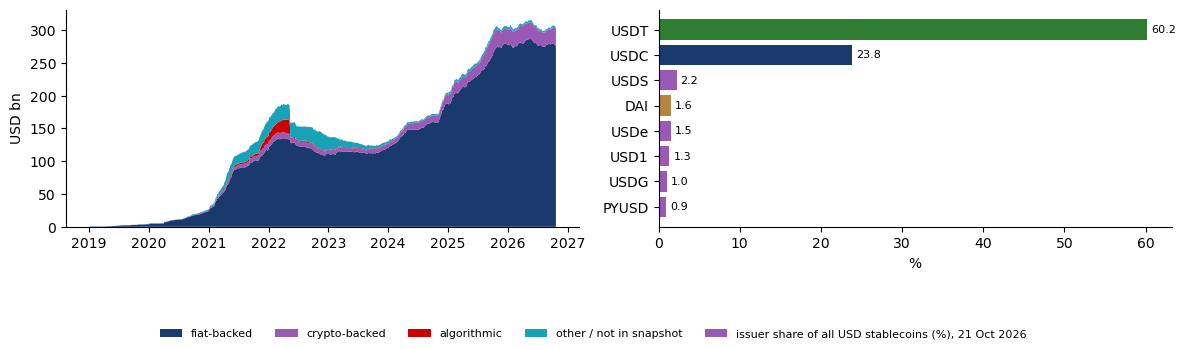

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].stackplot(by.index, [by[c].fillna(0) / 1e9 for c in order], colors=[BLUE, ETH, RED, TEAL], labels=order)
ax[0].set_ylabel('USD bn')
ax[1].barh(sh.index[::-1], sh.values[::-1], color=[COL.get(s, ETH) for s in sh.index[::-1]],
           label=f'issuer share of all USD stablecoins (%), {tot.index[-1]:%d %b %Y}')
for i, val in enumerate(sh.values[::-1]):
    ax[1].text(val + 0.5, i, f'{val:.1f}', va='center', fontsize=8)
ax[1].set_xlabel('%')
save(fig, 'ba_l4_supply', 0.17, ncol=5)

## Key numbers

In [7]:
dates = []
for y in ['2020-01-01', '2022-05-01', '2023-03-01', '2024-01-01', '2025-01-01']:
    dates.append(tot.index[tot.index.get_indexer([pd.Timestamp(y)], method='nearest')[0]])
dates.append(tot.index[-1])
print('Total supply of USD stablecoins (bn USD):')
print(pd.Series({d.date(): round(tot.loc[d] / 1e9, 1) for d in dates}, name='total supply (bn USD)').to_string())
print('\nShare of the total by mechanism on', tot.index[-1].date(), '(%):')
print((100 * by.iloc[-1] / tot.iloc[-1]).round(1).to_string())
print('\nShare of the total by issuer (%):')
print(sh.round(1).to_string())
print(f'\nUSDT + USDC together: {sh["USDT"] + sh["USDC"]:.1f}% of all USD stablecoins')

Total supply of USD stablecoins (bn USD):
2020-01-01      4.2
2022-05-01    187.1
2023-03-01    134.5
2024-01-01    129.8
2025-01-01    203.2
2026-10-21    303.4

Share of the total by mechanism on 2026-10-21 (%):
algorithmic                 0.0
crypto-backed               8.1
fiat-backed                90.9
other / not in snapshot     0.9

Share of the total by issuer (%):
USDT     60.2
USDC     23.8
USDS      2.2
DAI       1.6
USDe      1.5
USD1      1.3
USDG      1.0
PYUSD     0.9

USDT + USDC together: 84.0% of all USD stablecoins


**How to read it:** fiat-backed tokens make up about 91% of the supply and crypto-backed tokens about 8%; algorithmic designs almost vanished after TerraUSD.
Two issuers, Tether (USDT) and Circle (USDC), hold about 84% of the total, so a dislocation of USDC against USDT is a system-level event.